# 03 · Gradient Descent, the Zig-Zag, and Momentum

**Thesis reference:** Chapter 1, Section 1.4 (*Gradient Descent Toward the Minimum*): 1.4.3 *An Important Example with Zig-Zag*, 1.4.4 *Convergence Analysis*, 1.4.5 *Momentum and the Path of a Heavy Ball*.

The model problem is
$$f(x, y) = \tfrac12\,(x^2 + b\,y^2), \qquad 0 < b \le 1,$$
whose Hessian has eigenvalues $1$ and $b$, so the **condition number** is $\kappa = 1/b$.

* Steepest descent with exact line search zig-zags, and its error shrinks by the factor $\left(\frac{1-b}{1+b}\right)^2$ per step.
* The heavy-ball (momentum) method improves the factor to $\left(\frac{1-\sqrt b}{1+\sqrt b}\right)^2$, so $\kappa$ is replaced by $\sqrt{\kappa}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def make_problem(b):
    S = np.diag([1.0, b])
    f = lambda z: 0.5 * z @ S @ z
    grad = lambda z: S @ z
    return S, f, grad

## 1. Steepest descent with exact line search

For a quadratic, the best step along $-\nabla f$ is $s_k = \dfrac{g^Tg}{g^TSg}$. Starting from $(x_0, y_0) = (b, 1)$, the thesis derives the closed form
$$x_k = b\,r^k,\qquad y_k = (-r)^k,\qquad f(x_k,y_k) = r^{2k} f(x_0,y_0),\qquad r = \frac{b-1}{b+1}.$$

In [2]:
def steepest_descent_exact(b, iters):
    S, f, grad = make_problem(b)
    z = np.array([b, 1.0])
    path = [z.copy()]
    for _ in range(iters):
        g = grad(z)
        if g @ g < 1e-30:
            break
        z = z - (g @ g) / (g @ S @ g) * g
        path.append(z.copy())
    return np.array(path)

b = 0.1
path = steepest_descent_exact(b, 30)
r = (b - 1) / (b + 1)
k = np.arange(len(path))
closed_form = np.c_[b * r**k, (-r)**k]
print("max |computed - closed form| over 30 steps:", np.abs(path - closed_form).max())
print(f"per-step reduction of f: computed {(0.5*(path[1]@np.diag([1,b])@path[1]))/(0.5*(path[0]@np.diag([1,b])@path[0])):.6f}, "
      f"theory r^2 = {r**2:.6f}")

max |computed - closed form| over 30 steps: 1.6653345369377348e-16
per-step reduction of f: computed 0.669421, theory r^2 = 0.669421


## 2. The heavy ball: adding momentum

$$z_{k+1} = z_k - s\,\nabla f(z_k) + \beta\,(z_k - z_{k-1})$$
with the optimal choices $s = \left(\frac{2}{1+\sqrt b}\right)^2$ and $\beta = \left(\frac{1-\sqrt b}{1+\sqrt b}\right)^2$.

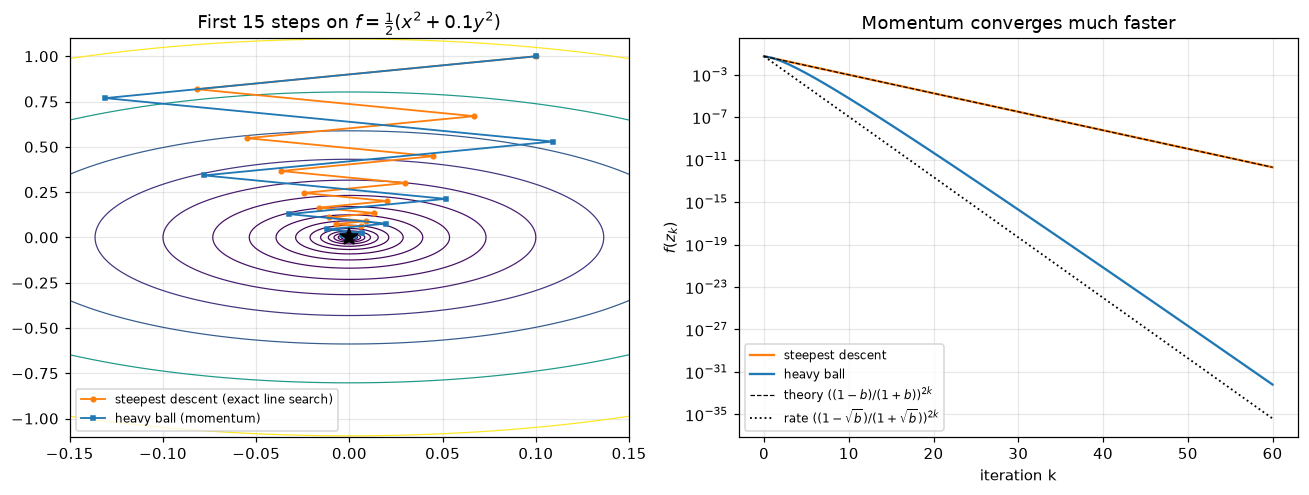

In [3]:
def heavy_ball(b, iters):
    S, f, grad = make_problem(b)
    s = (2 / (1 + np.sqrt(b)))**2
    beta = ((1 - np.sqrt(b)) / (1 + np.sqrt(b)))**2
    z_prev = z = np.array([b, 1.0])
    path = [z.copy()]
    for _ in range(iters):
        z, z_prev = z - s * grad(z) + beta * (z - z_prev), z
        path.append(z.copy())
    return np.array(path)

iters = 60
gd = steepest_descent_exact(b, iters)
hb = heavy_ball(b, iters)
_, f, _ = make_problem(b)

gx = np.linspace(-0.15, 0.15, 300)
gy = np.linspace(-1.1, 1.1, 300)
X, Y = np.meshgrid(gx, gy)
Z = 0.5 * (X**2 + b * Y**2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.contour(X, Y, Z, levels=np.geomspace(1e-5, 0.06, 15), cmap="viridis", linewidths=0.8)
ax.plot(gd[:15, 0], gd[:15, 1], "o-", color="tab:orange", ms=3, lw=1.2, label="steepest descent (exact line search)")
ax.plot(hb[:15, 0], hb[:15, 1], "s-", color="tab:blue", ms=3, lw=1.2, label="heavy ball (momentum)")
ax.plot(0, 0, "k*", ms=12)
ax.set_title(f"First 15 steps on $f=\\frac{{1}}{{2}}(x^2+{b}y^2)$")
ax.legend(fontsize=8)

ax = axes[1]
ax.semilogy([f(z) for z in gd], color="tab:orange", label="steepest descent")
ax.semilogy([f(z) for z in hb], color="tab:blue", label="heavy ball")
kk = np.arange(iters + 1)
f0 = f(np.array([b, 1.0]))
ax.semilogy(kk, f0 * ((1 - b) / (1 + b))**(2 * kk), "k--", lw=0.8, label=r"theory $((1-b)/(1+b))^{2k}$")
ax.semilogy(kk, f0 * ((1 - np.sqrt(b)) / (1 + np.sqrt(b)))**(2 * kk), "k:", lw=1.2,
            label=r"rate $((1-\sqrt{b})/(1+\sqrt{b}))^{2k}$")
ax.set_xlabel("iteration k")
ax.set_ylabel("$f(z_k)$")
ax.set_title("Momentum converges much faster")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "03_zigzag_vs_momentum.png", bbox_inches="tight")
plt.show()

## 3. Cost vs condition number

How many iterations does each method need to reduce $f$ by a factor of $10^{8}$, as the problem gets more ill-conditioned?
Theory predicts growth like $\kappa$ for steepest descent and like $\sqrt\kappa$ for momentum.

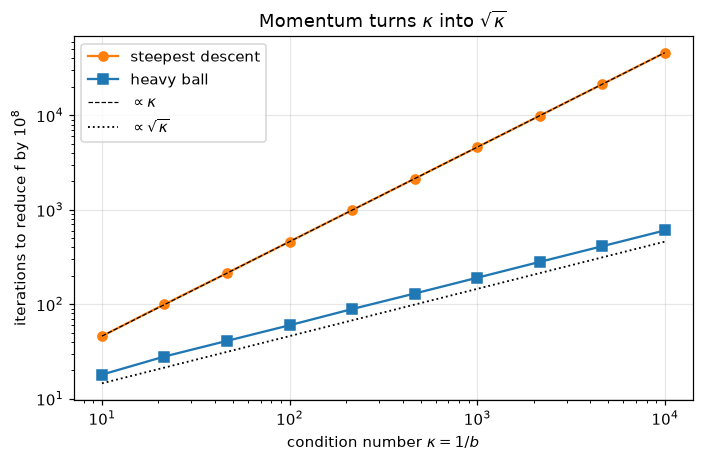

kappa =     10.0   steepest descent:     46   heavy ball:    18
kappa =     21.5   steepest descent:    100   heavy ball:    28
kappa =     46.4   steepest descent:    214   heavy ball:    41
kappa =    100.0   steepest descent:    461   heavy ball:    60
kappa =    215.4   steepest descent:    993   heavy ball:    89
kappa =    464.2   steepest descent:   2138   heavy ball:   130
kappa =   1000.0   steepest descent:   4606   heavy ball:   191
kappa =   2154.4   steepest descent:   9922   heavy ball:   281
kappa =   4641.6   steepest descent:  21376   heavy ball:   412
kappa =  10000.0   steepest descent:  46052   heavy ball:   605


In [4]:
def iterations_to_tol(method, b, tol=1e-8, max_iter=200_000):
    S, f, grad = make_problem(b)
    f0 = f(np.array([b, 1.0]))
    if method == "gd":
        z = np.array([b, 1.0])
        for k in range(1, max_iter):
            g = grad(z)
            z = z - (g @ g) / (g @ S @ g) * g
            if f(z) <= tol * f0:
                return k
    else:
        s = (2 / (1 + np.sqrt(b)))**2
        beta = ((1 - np.sqrt(b)) / (1 + np.sqrt(b)))**2
        z_prev = z = np.array([b, 1.0])
        for k in range(1, max_iter):
            z, z_prev = z - s * grad(z) + beta * (z - z_prev), z
            if f(z) <= tol * f0:
                return k
    return np.nan

kappas = np.geomspace(10, 1e4, 10)
gd_iters = [iterations_to_tol("gd", 1 / kap) for kap in kappas]
hb_iters = [iterations_to_tol("hb", 1 / kap) for kap in kappas]

plt.figure(figsize=(6.5, 4.3))
plt.loglog(kappas, gd_iters, "o-", color="tab:orange", label="steepest descent")
plt.loglog(kappas, hb_iters, "s-", color="tab:blue", label="heavy ball")
plt.loglog(kappas, kappas * np.log(1e8) / 4, "k--", lw=0.8, label=r"$\propto \kappa$")
plt.loglog(kappas, np.sqrt(kappas) * np.log(1e8) / 4, "k:", lw=1.2, label=r"$\propto \sqrt{\kappa}$")
plt.xlabel(r"condition number $\kappa = 1/b$")
plt.ylabel("iterations to reduce f by $10^8$")
plt.title("Momentum turns $\\kappa$ into $\\sqrt{\\kappa}$")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "03_iterations_vs_condition.png", bbox_inches="tight")
plt.show()

for kap, a, c in zip(kappas, gd_iters, hb_iters):
    print(f"kappa = {kap:8.1f}   steepest descent: {a:6d}   heavy ball: {c:5d}")

### Takeaways
* Ill-conditioning (a large $\kappa$) makes plain gradient descent zig-zag across a narrow valley.
* Momentum remembers the previous direction, damps the zig-zag, and reduces the iteration count from $O(\kappa)$ to $O(\sqrt\kappa)$.
* This is why momentum (and its descendants, Nesterov and ADAM) is standard in deep-learning optimizers. See notebook 04.